# Assignment 07: A First Machine Learning SDM

## BIO597 Spatial Analysis of Biodiversity

Repeat the workflow from Lab 07 for a Maine amphibian species of your choice. Focus on understanding what the model learns and what its predictions mean. You may reuse code from the lab.

## Deliverable

Submit this notebook with your completed code, figures, and short written answers, plus a saved suitability raster. There is no need to tune model settings or compare additional algorithms.


## 1. Import packages and load the data

Run this notebook from `docs/assignments`. Import the packages used in Lab 07. Load the two supplied files and display species counts.


In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray
import xarray as xr

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

In [3]:
amphibians = gpd.read_file("../data/amphibians+bioclim.geojson")
climate = xr.open_dataset("../data/maine_bioclim.nc")

amphibians["species"].value_counts().head(12)

species
Pseudacris crucifer          1722
Aquarana clamitans           1656
Anaxyrus americanus          1581
Boreorana sylvatica          1522
Lithobates catesbeianus      1451
Ambystoma maculatum          1214
Plethodon cinereus           1125
Lithobates palustris         1007
Dryophytes versicolor         714
Notophthalmus viridescens     573
Lithobates pipiens            325
Hemidactylium scutatum        226
Name: count, dtype: int64

## 2. Choose your species

Choose a common species other than the wood frog, with at least 500 records. Keep records with coordinate uncertainty below 100 m, as in the lab.


Number of records: 1017


(array([576., 151.,  83.,  71.,  34.,  23.,  35.,  25.,   8.,  11.]),
 array([ 1. , 10.8, 20.6, 30.4, 40.2, 50. , 59.8, 69.6, 79.4, 89.2, 99. ]),
 <BarContainer object of 10 artists>)

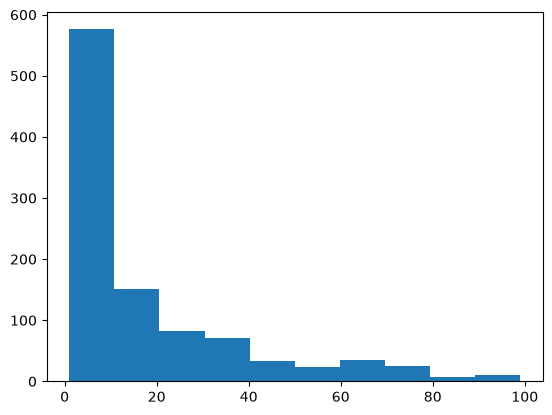

In [1]:
target_species = "Plethodon cinereus"

presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()

print("Number of records:", len(presence))

# Inspect the distribution of coordinate uncertainty
plt.hist(presence["coordinateUncertaintyInMeters"])

**Why did you choose this species?** Write one or two sentences.
- *Plethodon cinereus* is the Eastern Red-backed Salamander. In this dataset, it has 1017 records available (after filter for coordinate uncertainty) and is present within the study area (state of Maine). I think that salamanders are cute and would like to know more about what climate variables influence their distribution.

## 3. Keep all climate variables available

As in Lab 07, make a list called `climate_variables` containing `bio_1` through `bio_19`. We will choose the model predictors after preparing the modeling table.


In [6]:
climate_variables = ["bio_" + str(number) for number in range(1, 20)]

presence[climate_variables].head()

,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
10,7.436167,10.231000,27.868271,938.693848,25.612000,-11.100000,36.711998,3.229333,18.194666,18.858665,-4.422000,1150.0,119.0,80.0,13.355137,334.0,246.0,251.0,293.0
21,6.673833,13.075666,31.174105,1023.039246,27.271999,-14.672000,41.944000,1.999333,-5.200667,18.983999,-6.418000,1158.0,122.0,83.0,11.265086,329.0,258.0,289.0,275.0
68,6.673833,13.075666,31.174105,1023.039246,27.271999,-14.672000,41.944000,1.999333,-5.200667,18.983999,-6.418000,1158.0,122.0,83.0,11.265086,329.0,258.0,289.0,275.0
84,6.958833,10.551667,27.929239,966.069214,25.696001,-12.084001,37.780003,2.688667,17.873333,18.652666,-5.313334,1159.0,125.0,80.0,13.647320,340.0,257.0,258.0,278.0
91,7.217000,10.920667,28.076580,990.815125,26.368000,-12.528000,38.896000,2.772000,18.363333,19.229334,-5.396667,1110.0,108.0,73.0,10.873573,307.0,253.0,257.0,258.0


## 4. Prepare presence and background tables

Use the prepared climate values at the occurrence records directly, as in the revised lab. We do not need to match records to raster cells or join tables by coordinates.

The code below prepares the climate grid for background sampling and mapping. Each grid row is a cell, but each presence row is an occurrence record. Several presence records may therefore describe the same climate cell.


In [7]:
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
grid.head()

,x,y,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,...,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
146,-69.229167,47.437500,2.610167,10.487667,24.623560,1133.966675,23.148001,-19.444000,42.592003,16.066000,...,16.066000,-12.065333,1093.0,110.0,67.0,13.786905,317.0,227.0,317.0,231.0
147,-69.187500,47.437500,2.620167,10.551667,24.738974,1134.299316,23.200001,-19.452000,42.652000,16.072001,...,16.072001,-12.078667,1080.0,110.0,66.0,14.227962,316.0,223.0,316.0,228.0
148,-69.145833,47.437500,2.786333,10.607333,24.855499,1130.561035,23.344000,-19.332001,42.676003,16.170000,...,16.170000,-11.888667,1043.0,108.0,63.0,14.921009,307.0,211.0,307.0,222.0
246,-69.270833,47.395833,2.161333,10.447333,24.595850,1134.809448,22.668001,-19.808001,42.476002,15.676667,...,15.676667,-12.473333,1130.0,116.0,69.0,14.441315,332.0,233.0,332.0,237.0
247,-69.229167,47.395833,2.441500,10.566333,24.831577,1130.958252,22.968000,-19.584000,42.552002,15.872000,...,15.872000,-12.190666,1099.0,113.0,67.0,14.589335,323.0,226.0,323.0,231.0


In [8]:
# Keep the prepared predictors and remove records with missing climate values.
presence_data = presence[climate_variables].dropna().copy()
presence_data["observed"] = 1

print("Usable presence records:", len(presence_data))
presence_data.head()

Usable presence records: 1017


,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19,observed
10,7.436167,10.231000,27.868271,938.693848,25.612000,-11.100000,36.711998,3.229333,18.194666,18.858665,-4.422000,1150.0,119.0,80.0,13.355137,334.0,246.0,251.0,293.0,1
21,6.673833,13.075666,31.174105,1023.039246,27.271999,-14.672000,41.944000,1.999333,-5.200667,18.983999,-6.418000,1158.0,122.0,83.0,11.265086,329.0,258.0,289.0,275.0,1
68,6.673833,13.075666,31.174105,1023.039246,27.271999,-14.672000,41.944000,1.999333,-5.200667,18.983999,-6.418000,1158.0,122.0,83.0,11.265086,329.0,258.0,289.0,275.0,1
84,6.958833,10.551667,27.929239,966.069214,25.696001,-12.084001,37.780003,2.688667,17.873333,18.652666,-5.313334,1159.0,125.0,80.0,13.647320,340.0,257.0,258.0,278.0,1
91,7.217000,10.920667,28.076580,990.815125,26.368000,-12.528000,38.896000,2.772000,18.363333,19.229334,-5.396667,1110.0,108.0,73.0,10.873573,307.0,253.0,257.0,258.0,1


In [9]:
# Sample available environments, using one background row per presence record.
background = grid.sample(n=len(presence_data), random_state=597).copy()
background["observed"] = 0

model_data = pd.concat([presence_data, background], ignore_index=True)
model_data["observed"].value_counts()


observed
1    1017
0    1017
Name: count, dtype: int64

The missing-value cleanup keeps incomplete presence records out of both models. `random_state=597` makes the background sample repeatable. Background is sampled from the full valid grid, so it can include cells where the species has been recorded. It represents available environments, not confirmed absences.

## 5. Define predictors and response

Start with `features = ["bio_1"]`, annual mean temperature, to connect with last week's model. Set `X` to this predictor column and `y` to the `observed` labels. Only the selected climate columns belong in `X`; the background's coordinate columns are for mapping.


In [ ]:
features = ["bio_1"]
X = model_data[features]
y = model_data["observed"]

X.head()

,bio_1
0,7.436167
1,6.673833
2,6.673833
3,6.958833
4,7.217000


## 6. Split, fit, and predict

Split `model_data` into `train_data` (75%) and `test_data` (25%) with `random_state=597``, as in the lab

Fit a `RandomForestRegressor` using only `bio_1`, with 100 trees, `min_samples_leaf=5`, and `random_state=597`.


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

print("Training cells:", len(X_train))
print("Test cells:", len(X_test))

Training cells: 1525
Test cells: 509


In [12]:
model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=597,
)
model.fit(X_train, y_train)
test_prediction = model.predict(X_test)

## 7. Check the BIO1-only predictions

Calculate mean absolute error and store it as `bio1_error`. Plot test predictions for presence and background cells in overlapping histograms, as in the lab.


BIO1-only MAE: 0.234


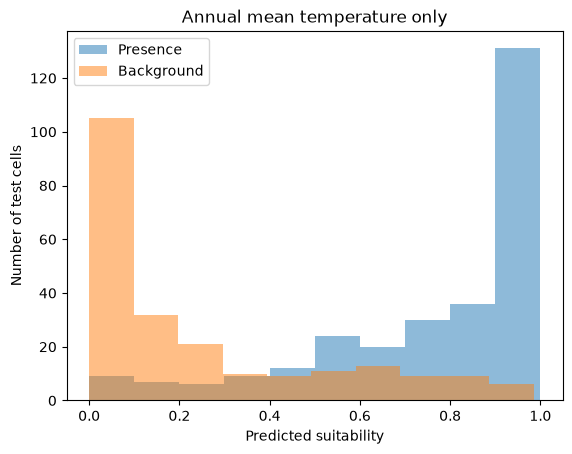

In [13]:
bio1_error = mean_absolute_error(y_test, test_prediction)
print("BIO1-only MAE:", round(bio1_error, 3))

plt.hist(test_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(test_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Annual mean temperature only")
plt.legend()
plt.show()

**Interpretation:** Do test presence cells generally receive higher scores? Why should we use withheld cells to check the model?

## 8. Add precipitation and compare MAE

Choose three new bioclim variables to test (you can look up the meanings of the variables
in the [bioclimatic variables documentation](https://www.worldclim.org/data/bioclim.html))

Change `features` to `["bio_X", "bio_XX", "bio_XX"]` (replacing the "X" values with the integer
index of the bioclim variables you chose). Create a new feature table (`X`) selecting just the features of interest and perform a new test/train split. Fit a new forest with these three predictors and calculate `three_variable_error`. Print both MAEs together.


In [ ]:
# Select the three predictor columns from the existing training and test tables.
# Fit three_variable_model and predict the same withheld cells.
# Calculate three_variable_error and print it beside bio1_error.

features = ["bio_1", "bio_12", "bio_15"]

# Update the feature table and create a new test/train split
X = model_data[features]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=10101,                 ## Good to evaluate how the test train split influences predictive power (model resilience)
)

three_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=2,
)

# Fit the model to the training data
three_variable_model.fit(X_train, y_train)

# Predict tarest for test features
three_variable_prediction = three_variable_model.predict(X_test)

# Evaluate mean absolute error of predictions vs known test values
three_variable_error = mean_absolute_error(y_test, three_variable_prediction)

print("BIO1-only MAE:", round(bio1_error, 3))
print("BIO1 + BIO12 + BIO15 MAE:", round(three_variable_error, 3))

In [ ]:
plt.hist(three_variable_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(three_variable_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Bio1, Bio12, & Bio15")
plt.legend()
plt.show()

**Interpretation:** Did the three new bioclim variables improve prediction error for your species? Explain why the new conditions you chose may or may not be relevant biologically.

## 9. Make a suitability map

Fit a new `final_model` using all modeling rows and the three predictors. Predict scores for `grid[features]`. Use the plotting recipe from Lab 07 to turn the suitability column into a raster and map it from 0 to 1.


In [ ]:
# Update X to include all three predictors.
# Fit final_model with the same forest settings.
# Add grid["suitability"], convert it to a raster named suitability, and plot it.


**Interpretation:** Which parts of Maine receive high scores? Why should we describe these as relative suitability rather than probability of occurrence?

## 10. Plot variable importance

Use `final_model.feature_importances_` and `pd.Series()` as in the lab to make a bar plot for the three predictors.


In [ ]:
# Make and label a variable-importance plot.


**Interpretation:** Which variable did your forest use most? Give one reason why this does not establish an ecological cause.

## 11. Save your map

Save `suitability` as `Assignment07_suitability.tif` using the same CRS and export commands as the lab.


In [ ]:
# Assign EPSG:4326 and save the suitability raster.


## 12. Run the training and prediction again including all 19 bioclim variables

**Think about:** Do you predict that more variables will improve the MAE of the model?

In [1]:
# Run the full analysis again but this time include all 19 bioclim variables
# feel free to copy/paste from cells above

## Final reflection

Answer in two or three sentences per question.

1. How does this week's BIO1-only random forest differ from last week's hand-built temperature curve?
2. What did the comparison with three predictors teach you? Would you expect more predictors always to reduce test error?
3. Several presence records can share a climate cell. Why might a random split then make prediction look easier than predicting a new location?
4. Name one habitat variable or sampling issue missing from your model. How might it affect the map?

## Submit your work

Restart the kernel and run the notebook from top to bottom. Check your figures, written answers, both MAEs, and saved raster. Commit and push the notebook and raster to your class GitHub repository.

```bash
git add docs/assignments/Assignment-07-MachineLearningSDM.ipynb docs/assignments/Assignment07_suitability.tif
git commit -m "Complete machine learning SDM assignment"
git push
```
